Chapter P4 ended with a chain of amino acids leaving the ribosome. This chapter is about what happens next: the chain folds into a precise 3D shape, and the shape decides what the protein does. Nearly every drug in chapter P13 works by fitting into a protein's shape. Structural biology, AlphaFold, molecular dynamics and docking (Part 3) are all about these shapes.

:::eli5
A protein is a long necklace of beads, with 20 kinds of bead. Some beads are oily and hate water, some love water, some are charged. Drop the necklace in water and it scrunches up by itself: the oily beads hide in the middle and the water-loving ones stay outside. Because the order of the beads is fixed by the gene, the necklace scrunches into the *same* shape every time. That shape has pockets and grooves, and the protein's job depends on what fits into them, like a key in a lock.
:::

## What proteins do

| Job | Example | Why you'll care |
|---|---|---|
| **Enzymes** speed up reactions | DNA polymerase, kinases, proteases | most drug targets |
| **Receptors** sense signals | EGFR, insulin receptor | cancer drugs block them (P9, P12) |
| **Transport and channels** | haemoglobin, ion channels | many drugs act on channels |
| **Structure** | collagen, actin, keratin | the cytoskeleton (P1) |
| **Motors** | myosin, kinesin | muscle, cell division |
| **Gene regulators** | transcription factors such as p53 and MYC | cell identity (P6), cancer (P12) |
| **Defence** | antibodies | immunotherapy (P10) |

## Amino acids: the 20 beads

Every amino acid has the same **backbone** (an amino group, a central carbon called Cα, and a carboxyl group) plus one of 20 different **side chains**. Joining the carboxyl of one to the amino group of the next makes a **peptide bond**, releasing water. A chain of amino acids is a **polypeptide**; it has an **N-terminus** (the start, with the free amino group) and a **C-terminus** (the end).

The side chains are what matter, and they fall into a few families: **hydrophobic** (oily: A, V, L, I, M, F, W), **polar** (S, T, Y, N, Q), **negatively charged** (D, E), **positively charged** (K, R, H), and three with **special shapes** (G, P, C). The third tab of the playground below lets you click through them all.

A useful number for each is its **hydropathy**: how much it prefers oil to water. The Kyte–Doolittle scale runs from +4.5 (isoleucine, very oily) to −4.5 (arginine, very water-loving).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from collections import Counter
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

KD = {"A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5, "Q": -3.5, "E": -3.5, "G": -0.4, "H": -3.2, "I": 4.5,
      "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8, "P": -1.6, "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2}
CLASS = {**dict.fromkeys("AVLIMFW", "hydrophobic"), **dict.fromkeys("STYNQ", "polar"), **dict.fromkeys("DE", "negative"),
         **dict.fromkeys("KRH", "positive"), **dict.fromkeys("GPC", "special")}
for c in ["hydrophobic", "polar", "negative", "positive", "special"]:
    members = [a for a in KD if CLASS[a] == c]
    print(f"{c:12s} {' '.join(members):16s} mean hydropathy {np.mean([KD[a] for a in members]):+.1f}")

hydrophobic  A I L M F W V    mean hydropathy +2.6
polar        N Q S T Y        mean hydropathy -2.0
negative     D E              mean hydropathy -3.5
positive     R H K            mean hydropathy -3.9
special      C G P            mean hydropathy +0.2


## Four levels of structure

Protein structure is described in four levels:

1. **Primary**: the amino-acid sequence itself, written N→C in one-letter code.
2. **Secondary**: local, regular patterns held by hydrogen bonds between backbone atoms. The two main ones are the **α-helix** (a spiral with 3.6 residues per turn) and the **β-sheet** (extended strands lying side by side).
3. **Tertiary**: the full 3D fold of one chain, held by the hydrophobic effect plus hydrogen bonds, salt bridges and sometimes disulfide bridges between cysteines.
4. **Quaternary**: several chains assembled into one machine.

Haemoglobin shows all four. Let's load its structure, solved by X-ray crystallography in 1984 and stored in the **Protein Data Bank** (PDB) as entry 4HHB. A PDB file is plain text listing the 3D coordinates (in ångströms, Å: 1 Å = 0.1 nm) of every atom.

In [2]:
from Bio.PDB import PDBParser, PPBuilder
parser = PDBParser(QUIET=True)
hb = parser.get_structure("haemoglobin", "datasets/4HHB.pdb")
print(open("datasets/4HHB.pdb").readline().strip())
three_to_one = {"ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E", "GLY": "G", "HIS": "H", "ILE": "I",
                "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F", "PRO": "P", "SER": "S", "THR": "T", "TRP": "W", "TYR": "Y", "VAL": "V"}
for chain in hb[0]:
    res = [r for r in chain if r.id[0] == " "]                # amino acids only (skip water and haem)
    het = sorted({r.get_resname() for r in chain if r.id[0].startswith("H_")})
    seq = "".join(three_to_one[r.get_resname()] for r in res)
    print(f"chain {chain.id}: {len(res)} amino acids, also contains {het}   {seq[:25]}...")
atoms = list(hb.get_atoms())
print(f"{len(atoms):,} atoms in total")

HEADER    OXYGEN TRANSPORT                        07-MAR-84   4HHB
chain A: 141 amino acids, also contains ['HEM']   VLSPADKTNVKAAWGKVGAHAGEYG...
chain B: 146 amino acids, also contains ['HEM', 'PO4']   VHLTPEEKSAVTALWGKVNVDEVGG...
chain C: 141 amino acids, also contains ['HEM']   VLSPADKTNVKAAWGKVGAHAGEYG...
chain D: 146 amino acids, also contains ['HEM', 'PO4']   VHLTPEEKSAVTALWGKVNVDEVGG...
4,779 atoms in total


Four chains: two α chains (141 amino acids) and two β chains (146, the *HBB* product from chapter P4). Each holds one **haem** group (HEM), an iron-containing ring that binds oxygen. That is the quaternary structure: an α₂β₂ team of four.

### Secondary structure: the Ramachandran plot

Each amino acid in the backbone can rotate around two bonds, by angles called **φ (phi)** and **ψ (psi)**. In 1963 G. N. Ramachandran showed that atoms bump into each other at most angle combinations, so only a few regions are allowed. Plotting real proteins shows the secondary structures as clusters:

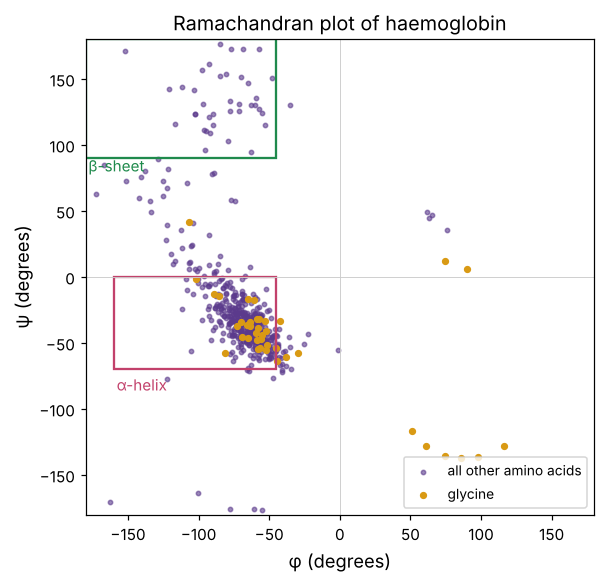

566 residues, 77% in the α-helix box; φ > 0 for 20% of glycines but 1% of others


In [3]:
phi, psi, names = [], [], []
for pp in PPBuilder().build_peptides(hb):
    for res, (a, b) in zip(pp, pp.get_phi_psi_list()):
        if a is not None and b is not None:
            phi.append(np.degrees(a)); psi.append(np.degrees(b)); names.append(res.get_resname())
phi, psi, names = np.array(phi), np.array(psi), np.array(names)

fig, ax = plt.subplots(figsize=(5.6, 5.4))
gly = names == "GLY"
ax.scatter(phi[~gly], psi[~gly], s=8, color="#5b3a8c", alpha=0.6, label="all other amino acids")
ax.scatter(phi[gly], psi[gly], s=14, color="#d99a14", label="glycine")
ax.add_patch(plt.Rectangle((-160, -70), 115, 70, fill=False, ec="#c2416b", lw=1.5)); ax.text(-158, -86, "α-helix", color="#c2416b")
ax.add_patch(plt.Rectangle((-180, 90), 135, 90, fill=False, ec="#1f8a4c", lw=1.5)); ax.text(-178, 80, "β-sheet", color="#1f8a4c")
ax.set_xlim(-180, 180); ax.set_ylim(-180, 180); ax.axhline(0, color="0.8", lw=0.6); ax.axvline(0, color="0.8", lw=0.6)
ax.set_xlabel("φ (degrees)"); ax.set_ylabel("ψ (degrees)"); ax.set_title("Ramachandran plot of haemoglobin"); ax.legend(loc="lower right", fontsize=9)
save_fig("ramachandran"); plt.show()
in_helix = (phi > -160) & (phi < -45) & (psi > -70) & (psi < 0)
R["n_angles"] = len(phi); R["helix_frac"] = f"{in_helix.mean():.0%}"
R["gly_right"] = f"{(phi[gly] > 0).mean():.0%}"; R["other_right"] = f"{(phi[~gly] > 0).mean():.0%}"
print(f"{len(phi)} residues, {in_helix.mean():.0%} in the α-helix box; φ > 0 for {(phi[gly] > 0).mean():.0%} of glycines but {(phi[~gly] > 0).mean():.0%} of others")

![Figure P5-1. Backbone angles of the 4 chains of haemoglobin. Most residues cluster in the α-helix region; glycine, with no side chain, can also reach angles (φ > 0) that are forbidden for other amino acids.](images/ramachandran.png)

Of 566 residues, 77% sit in the α-helix region: haemoglobin is almost all helix. Glycine, which has no side chain to bump into anything, is the exception that proves the rule: 20% of glycines have positive φ, against 1% of all other amino acids. Structure-checking software uses exactly this plot to flag errors in new structures, and it is the first thing to look at when validating a predicted model.

### Tertiary structure: oil inside, water outside

Why does a chain fold at all? Mainly the **hydrophobic effect** from chapter P2: oily side chains disrupt the hydrogen-bonded network of water, so the lowest-energy arrangement hides them inside, away from water. We can test that with real coordinates. For each amino acid, count how many other Cα atoms lie within 10 Å of its own Cα. Residues in the core have many neighbours; residues on the surface have few.

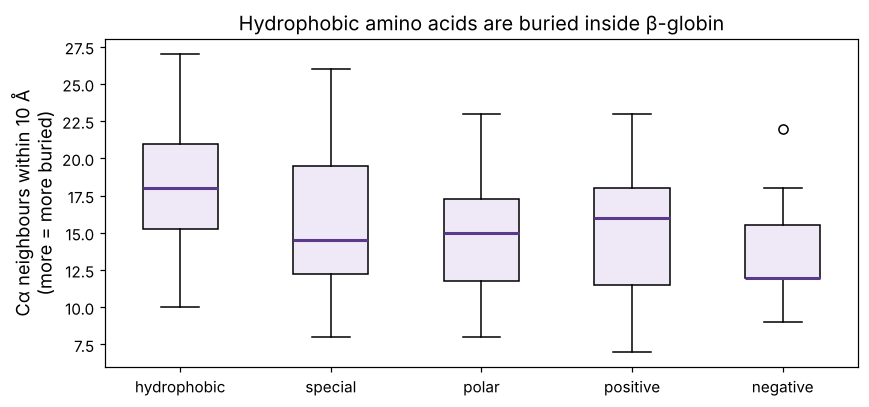

median neighbours: hydrophobic 18, charged 14; correlation with hydropathy r = 0.37


In [4]:
def chain_data(chain):
    res = [r for r in chain if r.id[0] == " " and "CA" in r]
    return "".join(three_to_one[r.get_resname()] for r in res), np.array([r["CA"].coord for r in res])

seq_b, ca_b = chain_data(hb[0]["B"])                          # one β-globin chain
dist = np.linalg.norm(ca_b[:, None, :] - ca_b[None, :, :], axis=-1)
neighbours = (dist < 10).sum(1) - 1

classes = ["hydrophobic", "special", "polar", "positive", "negative"]
groups = [neighbours[[CLASS[a] == c for a in seq_b]] for c in classes]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot(groups, tick_labels=classes, patch_artist=True, boxprops=dict(facecolor="#efe8f7"), medianprops=dict(color="#5b3a8c", lw=2))
ax.set_ylabel("Cα neighbours within 10 Å\n(more = more buried)"); ax.set_title("Hydrophobic amino acids are buried inside β-globin")
save_fig("burial"); plt.show()
r_corr = np.corrcoef([KD[a] for a in seq_b], neighbours)[0, 1]
R["burial_hyd"] = f"{np.median(groups[0]):.0f}"; R["burial_charged"] = f"{np.median(np.concatenate(groups[3:])):.0f}"; R["burial_r"] = f"{r_corr:.2f}"
print(f"median neighbours: hydrophobic {np.median(groups[0]):.0f}, charged {np.median(np.concatenate(groups[3:])):.0f}; correlation with hydropathy r = {r_corr:.2f}")

![Figure P5-2. Burial of each class of amino acid in a β-globin chain, measured by the number of nearby Cα atoms. Hydrophobic residues are packed in the core; charged residues sit on the surface.](images/burial.png)

Hydrophobic residues have a median of 18 neighbours, charged ones 14: oil in, charges out, exactly as the hydrophobic effect predicts. The correlation between hydropathy and burial is r = 0.37, clearly positive but far from perfect, because folding also depends on shape, packing and hydrogen bonds. This is also why the sickle-cell mutation (chapter P4) is so damaging: it puts an oily valine on the *surface*, where it sticks to a hydrophobic patch on a neighbouring haemoglobin.

### The contact map: a protein's fingerprint

A **contact map** marks every pair of residues whose Cα atoms are closer than 8 Å. Helices show up as thick bands just next to the diagonal (residues *i* and *i*+3 or *i*+4 touch), and contacts far from the diagonal show which distant parts of the chain are packed together. Here is myoglobin, the oxygen store of muscle and the first protein structure ever solved (by John Kendrew in 1958):

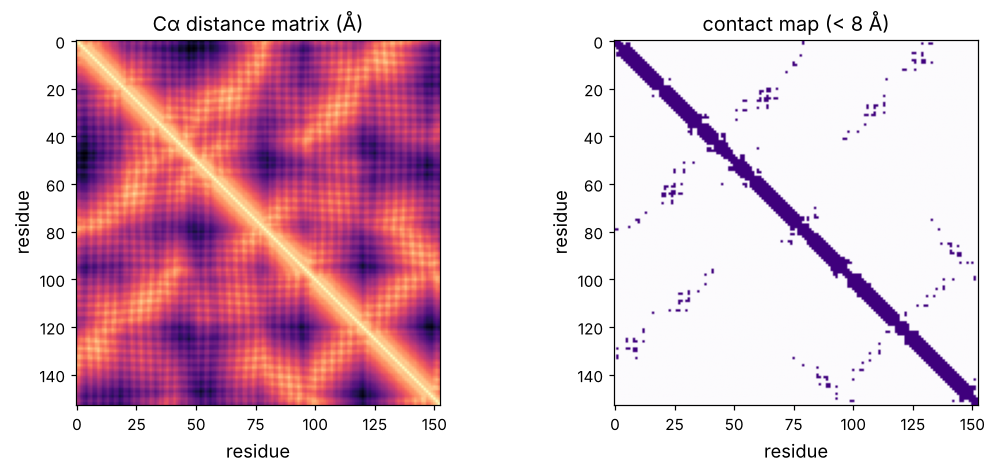

In [5]:
mb = parser.get_structure("myoglobin", "datasets/1MBN.pdb")
seq_m, ca_m = chain_data(next(mb[0].get_chains()))
dm = np.linalg.norm(ca_m[:, None] - ca_m[None], axis=-1)
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4))
axs[0].imshow(dm, cmap="magma_r"); axs[0].set_title("Cα distance matrix (Å)")
axs[1].imshow(dm < 8, cmap="Purples"); axs[1].set_title("contact map (< 8 Å)")
for a in axs: a.set_xlabel("residue"); a.set_ylabel("residue")
save_fig("contact_map"); plt.show()
R["mb_len"] = len(seq_m)

![Figure P5-3. Left: distances between every pair of Cα atoms in myoglobin. Right: the contact map. The thick diagonal bands are α-helices; off-diagonal patches are helices packed against each other.](images/contact_map.png)

The 3D structure of a 153-residue protein is almost fully determined by this 2D picture. That observation is central to modern structure prediction: **AlphaFold 2** (2020) learned to predict a protein's distance matrix from its sequence (and from evolutionary information in related sequences), then built a 3D structure to match. Chapter 10 builds a small version of this idea.

### How big is a protein?

Proteins pack as densely as organic crystals, with no holes inside. If they were solid balls, the radius would grow as the cube root of the number of residues *N*. Let's check with ten structures of very different proteins, measuring the **radius of gyration** (the root-mean-square distance of the Cα atoms from their centre):

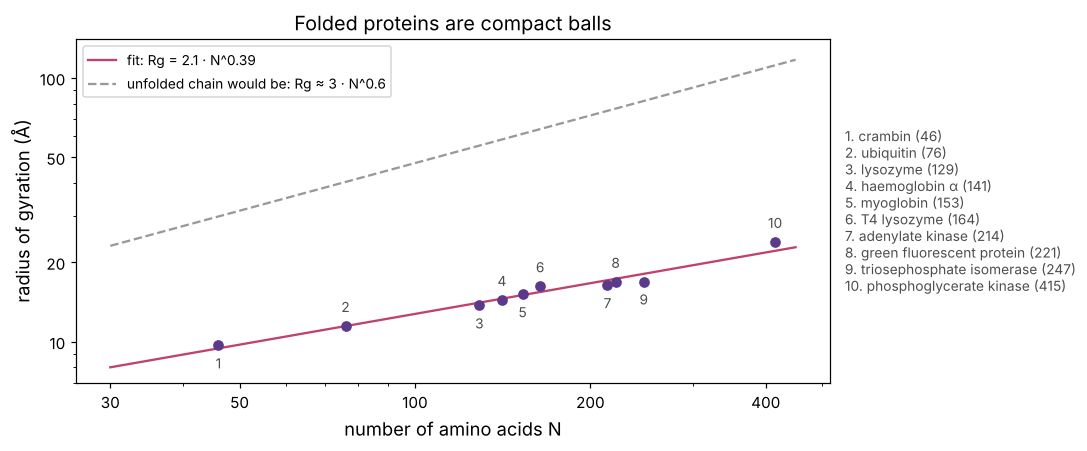

fitted exponent 0.39 (a solid ball would give 1/3 = 0.33)


In [6]:
pdbs = {"1CRN": "crambin", "1UBQ": "ubiquitin", "1LYZ": "lysozyme", "4HHB": "haemoglobin α", "1MBN": "myoglobin",
        "2LZM": "T4 lysozyme", "1AKE": "adenylate kinase", "1EMA": "green fluorescent protein", "1TIM": "triosephosphate isomerase",
        "3PGK": "phosphoglycerate kinase"}
N, Rg = [], []
for pid, name in pdbs.items():
    st = parser.get_structure(pid, f"datasets/{pid}.pdb")
    _, ca = chain_data(next(st[0].get_chains()))
    N.append(len(ca)); Rg.append(np.sqrt(((ca - ca.mean(0)) ** 2).sum(1).mean()))
N, Rg = np.array(N), np.array(Rg)
slope, logc = np.polyfit(np.log(N), np.log(Rg), 1)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.scatter(N, Rg, color="#5b3a8c", zorder=3)
order = np.argsort(N)                                          # number the points from smallest to largest
for k, i in enumerate(order):
    ax.annotate(str(k + 1), (N[i], Rg[i]), textcoords="offset points", xytext=(0, 9 if k % 2 else -15), ha="center", fontsize=9, color="0.3")
ax.text(1.02, 0.5, "\n".join(f"{k + 1}. {list(pdbs.values())[i]} ({N[i]})" for k, i in enumerate(order)),
        transform=ax.transAxes, va="center", fontsize=9, color="0.3")
nn = np.linspace(30, 450, 100)
ax.plot(nn, np.exp(logc) * nn ** slope, color="#c2416b", label=f"fit: Rg = {np.exp(logc):.1f} · N^{slope:.2f}")
ax.plot(nn, 3.0 * nn ** 0.6, color="0.6", ls="--", label="unfolded chain would be: Rg ≈ 3 · N^0.6")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("number of amino acids N"); ax.set_ylabel("radius of gyration (Å)"); ax.set_ylim(7, 140)
from matplotlib.ticker import ScalarFormatter, NullFormatter
ax.xaxis.set_major_formatter(ScalarFormatter()); ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xticks([30, 50, 100, 200, 400])
ax.yaxis.set_major_formatter(ScalarFormatter()); ax.yaxis.set_minor_formatter(NullFormatter()); ax.set_yticks([10, 20, 50, 100])
ax.legend(fontsize=9); ax.set_title("Folded proteins are compact balls")
save_fig("rg_scaling"); plt.show()
R["slope"] = f"{slope:.2f}"; R["c"] = f"{np.exp(logc):.1f}"
print(f"fitted exponent {slope:.2f} (a solid ball would give 1/3 = 0.33)")

![Figure P5-4. Radius of gyration against length for ten folded proteins (log scales). The fitted exponent is close to 1/3, the value for a compact ball; an unfolded chain would be much larger and grow faster.](images/rg_scaling.png)

The fitted exponent is 0.39, close to the 1/3 of a solid ball and far from the roughly 0.6 of a floppy unfolded chain. A folded protein of a few hundred residues is only about 4–5 nm across, which matches the "typical protein, 5 nm" in chapter P1.

## Folding: how does the chain find its shape?

In 1961 Christian Anfinsen unfolded the enzyme ribonuclease with chemicals, then removed them. The enzyme refolded by itself and worked again. Conclusion: **the sequence alone contains the information for the fold** (Anfinsen's dogma). That is why predicting structure from sequence is possible in principle.

But how does the chain search for its fold? Cyrus Levinthal pointed out a paradox:

In [7]:
n_res, states_per_res, tries_per_s = 100, 3, 1e13
total = states_per_res ** n_res
years = total / tries_per_s / 3.15e7
print(f"{states_per_res}^{n_res} = {total:.1e} shapes; at {tries_per_s:.0e} shapes per second: {years:.0e} years")
print(f"age of the universe: 1.4e+10 years")
R["lev_years"] = f"10^{np.log10(years):.0f}"

3^100 = 5.2e+47 shapes; at 1e+13 shapes per second: 2e+27 years
age of the universe: 1.4e+10 years


Trying every shape of a 100-residue chain would take about 10^27 years, yet real proteins fold in microseconds to seconds. The answer is that folding is not a random search. Each small step that buries some hydrophobic surface lowers the energy, so the chain slides downhill in a **folding funnel**: local helices form fast, hydrophobic parts collapse together, and the details settle last.

The first tab of the playground lets you watch this in the classic **HP model**, a toy protein on a grid with only two kinds of bead, hydrophobic (H) and polar (P). Each H–H contact lowers the energy by 1. Press Run and watch the hydrophobic core form; raise the temperature and watch it melt. Real molecular dynamics (chapter 12) works the same way in spirit, with real atoms and real forces.

::playground animations/protein_lab.html 640

:::bio
Folding can go wrong. **Chaperone** proteins (such as HSP70 and HSP90) help new chains fold and refold damaged ones; cancer cells depend heavily on them, and HSP90 inhibitors have been tested as cancer drugs. Misfolded proteins that clump into **amyloid** fibres cause Alzheimer's (amyloid-β and tau), Parkinson's (α-synuclein) and prion diseases.
:::

## Membrane proteins: a hydrophobic signature

Proteins that sit in the oily cell membrane must expose oily side chains to the membrane's interior. A stretch of about 20 hydrophobic amino acids is just long enough to cross the membrane as an α-helix. So a **hydropathy plot**, the average hydropathy in a sliding window along the sequence, reveals membrane-crossing helices straight from the sequence. We fetched two sequences from **UniProt**, the main protein sequence database: bacteriorhodopsin (a light-driven pump from a salt-loving microbe) and human EGFR (a receptor targeted by lung cancer drugs).

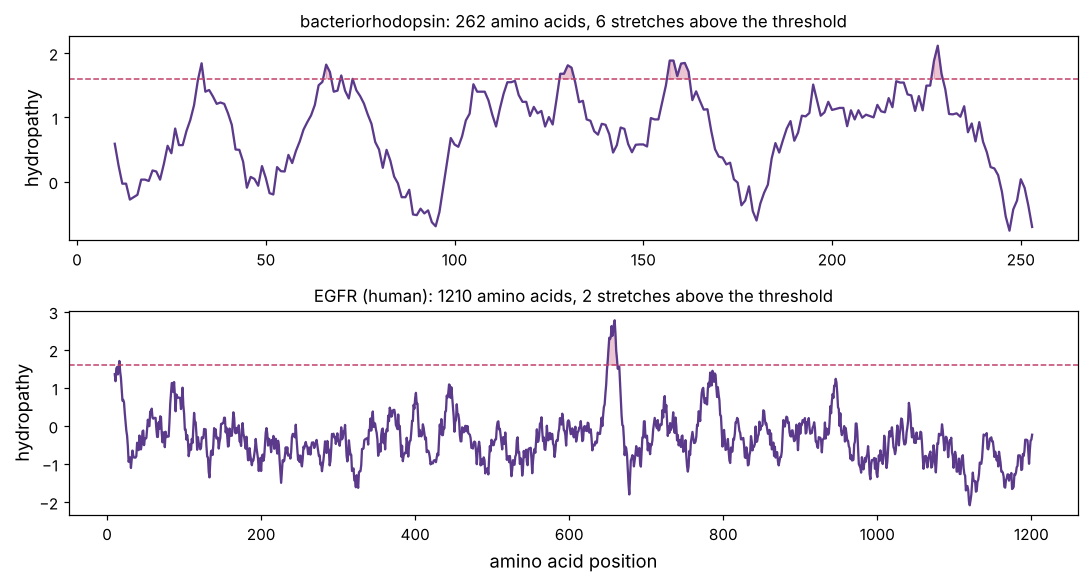

{'bacteriorhodopsin': 6, 'EGFR (human)': 2}


In [8]:
def read_fasta(path):
    lines = Path(path).read_text().splitlines()
    return lines[0][1:], "".join(lines[1:])

def hydropathy(seq, w=19):
    vals = np.array([KD[a] for a in seq])
    return np.convolve(vals, np.ones(w) / w, mode="valid")

fig, axs = plt.subplots(2, 1, figsize=(10, 5.4))
tm_counts = {}
for ax, (path, title) in zip(axs, [("datasets/bR_P02945.fasta", "bacteriorhodopsin"), ("datasets/EGFR_P00533.fasta", "EGFR (human)")]):
    header, seq = read_fasta(path)
    hp = hydropathy(seq); x = np.arange(len(hp)) + 10
    ax.plot(x, hp, color="#5b3a8c"); ax.axhline(1.6, color="#c2416b", ls="--", lw=1)
    ax.fill_between(x, 1.6, hp, where=hp > 1.6, color="#c2416b", alpha=0.3)
    above = hp > 1.6
    peaks = np.sum(above[1:] & ~above[:-1]) + above[0]
    tm_counts[title] = int(peaks)
    ax.set_title(f"{title}: {len(seq)} amino acids, {peaks} stretches above the threshold", fontsize=11); ax.set_ylabel("hydropathy")
axs[1].set_xlabel("amino acid position")
save_fig("hydropathy"); plt.show()
R["br_tm"] = tm_counts["bacteriorhodopsin"]; R["egfr_tm"] = tm_counts["EGFR (human)"]
print(tm_counts)

![Figure P5-5. Hydropathy plots (19-residue window, Kyte–Doolittle scale). Peaks above 1.6 (red) are candidate membrane-crossing helices. Bacteriorhodopsin crosses the membrane seven times; EGFR crosses once, with its signal peptide at the very start also standing out.](images/hydropathy.png)

The simple threshold finds 6 peaks in bacteriorhodopsin and 2 in EGFR. Bacteriorhodopsin really has seven membrane helices, the same seven-helix design as the largest family of human drug targets, the **G-protein-coupled receptors**; a 19-residue window with a fixed threshold misses or merges some of them, which is why modern predictors use machine learning. EGFR has one membrane helix near position 650 (clearly visible) plus, at the very start, a hydrophobic **signal peptide** that steers the new protein into the membrane and is then cut off. EGFR's outside part binds a growth-factor signal; its inside part is an enzyme (a kinase) that drugs such as erlotinib and osimertinib switch off (chapters P9, P12, 15).

## Enzymes: catalysts made of protein

An **enzyme** speeds up a reaction without being used up. It does not change the equilibrium (chapter P2: that is set by ΔG); it lowers the **activation energy**, the hill that molecules must climb to react. Speed-ups are enormous: the enzyme orotidine decarboxylase makes its reaction about 10¹⁷ times faster. The reacting molecule, the **substrate**, binds in a pocket called the **active site**, whose shape and chemistry fit the reaction's transition state.

The speed of an enzyme reaction follows the **Michaelis–Menten** equation:

:::math
$$v = \frac{V_{\max}\,[S]}{K_m + [S]}, \qquad V_{\max} = k_\text{cat}\,[E]_\text{total}$$

- $[S]$: substrate concentration.
- $V_{\max}$: the top speed, when every enzyme molecule is busy.
- $k_\text{cat}$: the **turnover number**, reactions per second per enzyme molecule at top speed.
- $K_m$: the substrate concentration giving half the top speed. Small $K_m$ means the enzyme works well even at low substrate.

At low $[S]$, $v \approx (k_\text{cat}/K_m)[E][S]$, so $k_\text{cat}/K_m$ measures overall efficiency. Its physical limit is set by how fast molecules can diffuse together, about $10^8$–$10^9\ \text{M}^{-1}\text{s}^{-1}$.
:::

Biochemists measure reaction speed at several substrate concentrations and fit the curve. Here is that workflow on simulated measurements with 5% noise:

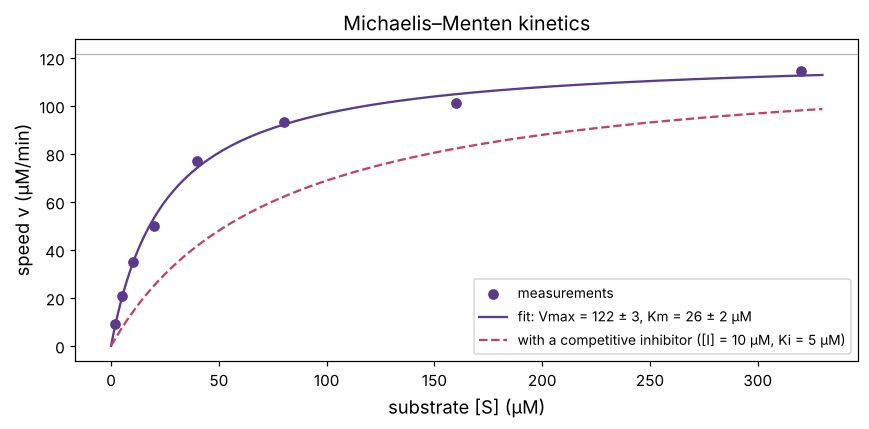

fitted Vmax 121.6 (true 120.0), Km 25.5 (true 25.0)


In [9]:
from scipy.optimize import curve_fit
rng = np.random.default_rng(1)
true_vmax, true_km = 120.0, 25.0                       # µM/min and µM
S = np.array([2, 5, 10, 20, 40, 80, 160, 320], float)
v = true_vmax * S / (true_km + S) * (1 + 0.05 * rng.standard_normal(S.size))

mm = lambda s, vmax, km: vmax * s / (km + s)
(vmax_fit, km_fit), cov = curve_fit(mm, S, v, p0=[100, 10])
err = np.sqrt(np.diag(cov))

# a competitive inhibitor raises the apparent Km by (1 + [I]/Ki)
Ki, I = 5.0, 10.0
ss = np.linspace(0, 330, 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(S, v, color="#5b3a8c", zorder=3, label="measurements")
ax.plot(ss, mm(ss, vmax_fit, km_fit), color="#5b3a8c", label=f"fit: Vmax = {vmax_fit:.0f} ± {err[0]:.0f}, Km = {km_fit:.0f} ± {err[1]:.0f} µM")
ax.plot(ss, mm(ss, vmax_fit, km_fit * (1 + I / Ki)), color="#c2416b", ls="--", label=f"with a competitive inhibitor ([I] = {I:.0f} µM, Ki = {Ki:.0f} µM)")
ax.axhline(vmax_fit, color="0.7", lw=0.8); ax.set_xlabel("substrate [S] (µM)"); ax.set_ylabel("speed v (µM/min)"); ax.legend(fontsize=9)
ax.set_title("Michaelis–Menten kinetics")
save_fig("michaelis"); plt.show()
R["vmax"] = f"{vmax_fit:.0f}"; R["km"] = f"{km_fit:.0f}"; R["km_app"] = f"{km_fit * (1 + I / Ki):.0f}"
print(f"fitted Vmax {vmax_fit:.1f} (true {true_vmax}), Km {km_fit:.1f} (true {true_km})")

![Figure P5-6. Simulated enzyme measurements, the fitted Michaelis–Menten curve, and the same enzyme with a competitive inhibitor. The inhibitor shifts the curve to the right without lowering the top speed.](images/michaelis.png)

The fit recovers Vmax ≈ 122 and Km ≈ 26 µM, close to the true 120 and 25. A **competitive inhibitor** sits in the active site and competes with the substrate. It raises the apparent Km (here to about 77 µM) but enough substrate still reaches full speed. Many drugs are competitive inhibitors: statins block the cholesterol-making enzyme HMG-CoA reductase, and most kinase inhibitors in cancer compete with ATP for the kinase's active site. The second tab of the playground lets you vary Km, Vmax and an inhibitor and see both kinds of inhibition.

In [10]:
enzymes = {"carbonic anhydrase": (1e6, 12e-3), "catalase": (4e7, 1.1), "acetylcholinesterase": (1.4e4, 9e-5),
           "chymotrypsin": (1.9e2, 6.6e-4), "lysozyme": (0.5, 6e-6)}
for name, (kcat, km_M) in enzymes.items():
    print(f"{name:22s} kcat {kcat:9.3g} per s   Km {km_M * 1e3:8.3g} mM   kcat/Km {kcat / km_M:9.2g} per M per s")

carbonic anhydrase     kcat     1e+06 per s   Km       12 mM   kcat/Km   8.3e+07 per M per s
catalase               kcat     4e+07 per s   Km  1.1e+03 mM   kcat/Km   3.6e+07 per M per s
acetylcholinesterase   kcat   1.4e+04 per s   Km     0.09 mM   kcat/Km   1.6e+08 per M per s
chymotrypsin           kcat       190 per s   Km     0.66 mM   kcat/Km   2.9e+05 per M per s
lysozyme               kcat       0.5 per s   Km    0.006 mM   kcat/Km   8.3e+04 per M per s


Turnover numbers span about eight orders of magnitude. Acetylcholinesterase, which clears the signal molecule acetylcholine at nerve–muscle junctions, has a kcat/Km near the diffusion limit; it is about as fast as an enzyme can be. Nerve agents and some insecticides work by blocking it.

## After folding: modifications and destruction

A finished protein is not static:

- **Post-translational modifications** change its behaviour. The most important is **phosphorylation**: kinases attach a phosphate group to serine, threonine or tyrosine, switching the protein on or off. There are about 500 human kinases; chapter P9 shows how they pass signals in chains.
- **Degradation**: proteins are tagged for destruction with chains of a small protein called **ubiquitin** (structure 1UBQ above) and shredded by the **proteasome**. Lifetimes range from minutes (p53, constantly destroyed until DNA damage stabilises it) to years (lens crystallins in your eye). The proteasome inhibitor bortezomib treats the blood cancer multiple myeloma, and new **PROTAC** drugs deliberately tag a target protein for destruction.

:::data
Where protein data lives: **UniProt** (sequences and annotations for about 250 million proteins), the **PDB** (more than 220,000 experimentally solved 3D structures), and the **AlphaFold Database** (predicted structures for more than 200 million proteins). All are free. The four files we used here came from the PDB and UniProt with one web request each.
:::

## Summary

| Idea | One line |
|---|---|
| Amino acids | a shared backbone plus one of 20 side chains: oily, polar, charged or special |
| Four levels | sequence → helices and sheets → 3D fold → multi-chain assemblies |
| Why it folds | hydrophobic side chains hide from water; sequence determines the fold |
| Contact map | 2D fingerprint of the 3D structure; what AlphaFold learned to predict |
| Enzymes | lower the activation energy; speed follows v = Vmax[S]/(Km+[S]) |
| Inhibitors | competitive ones raise Km; non-competitive ones lower Vmax |

:::check
1. Which would you expect on the surface of a soluble protein, lysine or leucine? *(Lysine: charged and water-loving.)*
2. What does a stretch of about 20 hydrophobic residues in a sequence suggest? *(A membrane-crossing helix.)*
3. Why is glycine special on a Ramachandran plot? *(It has no side chain, so it can adopt angles that are forbidden for other amino acids.)*
4. An enzyme has Km = 10 µM. Roughly what fraction of Vmax does it reach at 10 µM substrate? At 90 µM? *(Half; 90%.)*
5. Can a competitive inhibitor's effect be overcome by adding more substrate? *(Yes; the top speed is unchanged.)*
:::

:::exercise
Use the haemoglobin structure to find the amino acids that hold each haem group in place: for chain A, list every residue with any atom within 4 Å of any haem atom. Which residue is bonded to the iron? (Hint: look for the histidine closest to the Fe atom.)
:::

<details><summary>Solution</summary>

In [11]:
from Bio.PDB import NeighborSearch
chain = hb[0]["A"]
heme = [r for r in chain if r.get_resname() == "HEM"][0]
ns = NeighborSearch([a for a in chain.get_atoms() if a.get_parent().id[0] == " "])
contacts = sorted({a.get_parent() for atom in heme for a in ns.search(atom.coord, 4.0)}, key=lambda r: r.id[1])
print("residues within 4 Å of the haem:", ", ".join(f"{r.get_resname()}{r.id[1]}" for r in contacts))
fe = heme["FE"]
his = min((r for r in chain if r.get_resname() == "HIS"), key=lambda r: r["NE2"] - fe)
print(f"closest histidine to the iron: {his.get_resname()}{his.id[1]}, NE2–Fe distance {his['NE2'] - fe:.2f} Å")

residues within 4 Å of the haem: TYR42, PHE43, HIS45, PHE46, HIS58, LYS61, VAL62, LEU83, LEU86, HIS87, LEU91, VAL93, ASN97, PHE98, LEU101, LEU136
closest histidine to the iron: HIS87, NE2–Fe distance 2.14 Å


The haem sits in a pocket lined mostly with hydrophobic residues (leucines, phenylalanines, valines), which keeps water away from the iron. The iron is held by **His87**, the "proximal histidine", about 2 Å away. A second histidine (His58) sits on the other side, where oxygen binds. Mutations at these positions cause inherited haemoglobin disorders.

</details>